In [12]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from pathlib import Path
import os
import sys
sys.path.append('../')
sys.path.append('./scripts/')
sys.path.append('../scripts/')
import numpy as np
import xarray as xr
import functions as f
from visualization.visualization import PhenologyVisualization
from pixel_metric_calcs.bloom_assemble import BloomAssemble
import seaborn as sns

In [2]:
var = 'chla'
lakeID = 300000138
start_year = 2002
end_year = 2023
qa_set = [0,1]

In [29]:
f.qa_set_to_str(qa_set)

'qa01'

In [3]:
%matplotlib inline

In [13]:
sns.set_context('talk')

In [4]:
lake_shp_fp = "C:\\Users\\schelian\\cci-cyano-production\\shapefiles\\lakes_cci_v2.0.2_data_availability_shp\\lakescci_v2.0.2_data-availability.shp"
data_dir = Path("D:/phenology_data/v3.0")

In [5]:
PhenologyVisualization.set_shapefile_path(lake_shp_fp)
e_path = data_dir /  "extract"  / var / f"{lakeID}.nc"
p_path = data_dir / "phenology" / var / f"{lakeID}.nc"
eda_instance = PhenologyVisualization(e_path, p_path)

bloom_assembly_fp = f.construct_bloom_assembly_filename(lakeID)
bloom_assembly_dir = f.construct_bloom_assembly_dirpath(data_dir,var)

bloom_prob_fp = f.construct_bloom_prob_filename(lakeID,start_year,end_year, qa_label = f.qa_set_to_str(qa_set))
bloom_prob_dir = f.construct_bloom_prob_dirpath(data_dir,var)

C:\Users\schelian\AppData\Local\miniforge3\envs\esaclimate\Lib\site-packages\pyogrio\core.py:38: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


In [6]:
assembly_df = BloomAssemble.read_cached_metric(bloom_assembly_dir / bloom_assembly_fp)
assembly_df.head()

,primary,qa_column,secondary,i,j,year.DOY
0,1,NaN,0,0,1,2003.172
1,1,NaN,0,0,1,2004.017
2,1,NaN,0,0,1,2005.100
3,1,NaN,0,0,1,2006.040
4,1,NaN,0,0,1,2006.204


In [7]:
paired_df = assembly_df.set_index('year.DOY').groupby(['i','j']).apply(f.find_preceding_and_following, include_groups=False).dropna()
paired_df['year'] = paired_df.index.get_level_values(2).astype(int)
paired_df

prev_var1_time  next_var2_time  qa_column  year
i  j  year.DOY                                                 
0  1  2003.205        2003.172        2003.235        2.0  2003
      2004.046        2004.017        2004.091        2.0  2004
      2005.158        2005.100        2005.196        2.0  2005
      2006.103        2006.040        2006.126        2.0  2006
      2006.222        2006.204        2006.248        2.0  2006
...                        ...             ...        ...   ...
41 96 2020.097        2020.078        2020.115        1.0  2020
      2020.360        2020.336        2021.016        2.0  2020
      2021.210        2021.190        2021.231        1.0  2021
      2022.028        2021.364        2022.054        2.0  2022
      2022.227        2022.198        2022.257        1.0  2022

[33460 rows x 4 columns]

In [8]:
def filter_pairs_qa_year(paired_df, year_list, qa_vals):
    if "year" not in paired_df.columns:
        paired_df = paired_df.copy()
        paired_df['year'] = paired_df.index.get_level_values('year.DOY').astype(int)
    if isinstance(qa_vals, str):
        qa_vals = f.qa_str_to_set(qa_vals)
    if not qa_vals:
        qa_vals = {0,1,2}
    filtered_df = paired_df.loc[paired_df['year'].isin(year_list) & paired_df['qa_column'].isin(qa_vals)].copy()
    filtered_df['qa_column'] = filtered_df['qa_column'].astype('category')
    return filtered_df

In [9]:
def yearDOY_to_DOY(df, col_list):
    for col in col_list:
        df[f"{col}_DOY"] = (df[col] % 1 * 1000).round().astype(int)
    return df

In [10]:
def prep_df_for_plotting(df):
    df = yearDOY_to_DOY(df, ['prev_var1_time', 'next_var2_time'])
    df.rename(columns={'prev_var1_time_DOY':'x_DOY','next_var2_time_DOY':'y_DOY'},inplace=True)
    df.loc[df["y_DOY"] < df["x_DOY"],"y_DOY"] += 365
    return df

In [11]:
qa_colors = {
    0: "#15B01A",  # green
    1: "yellow",
    2: "red",
}

qa_cmap = ListedColormap([qa_colors[q] for q in sorted(qa_set)])

In [16]:
os.getcwd()

'C:\\Users\\schelian\\cci-cyano-production\\notebooks'

2005


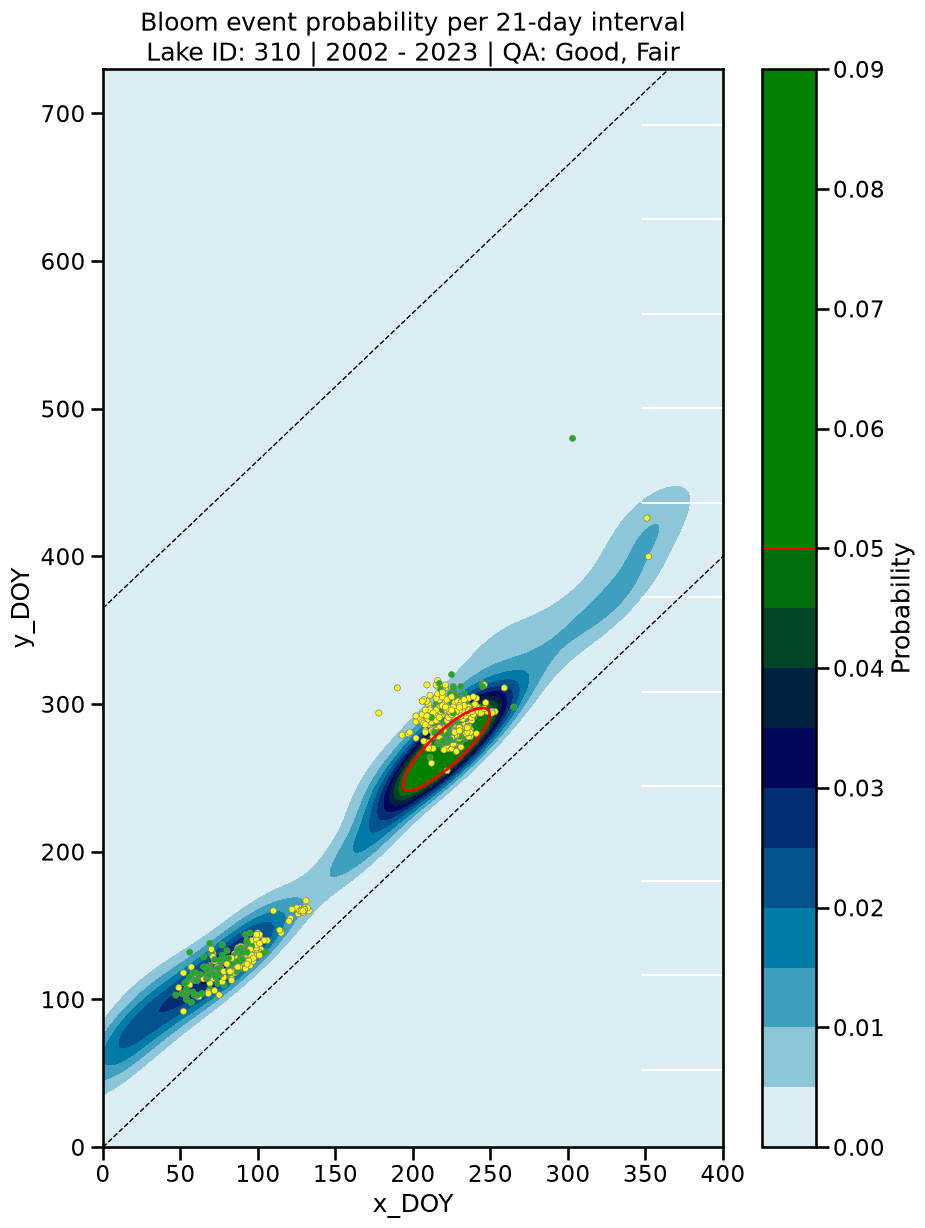

2006


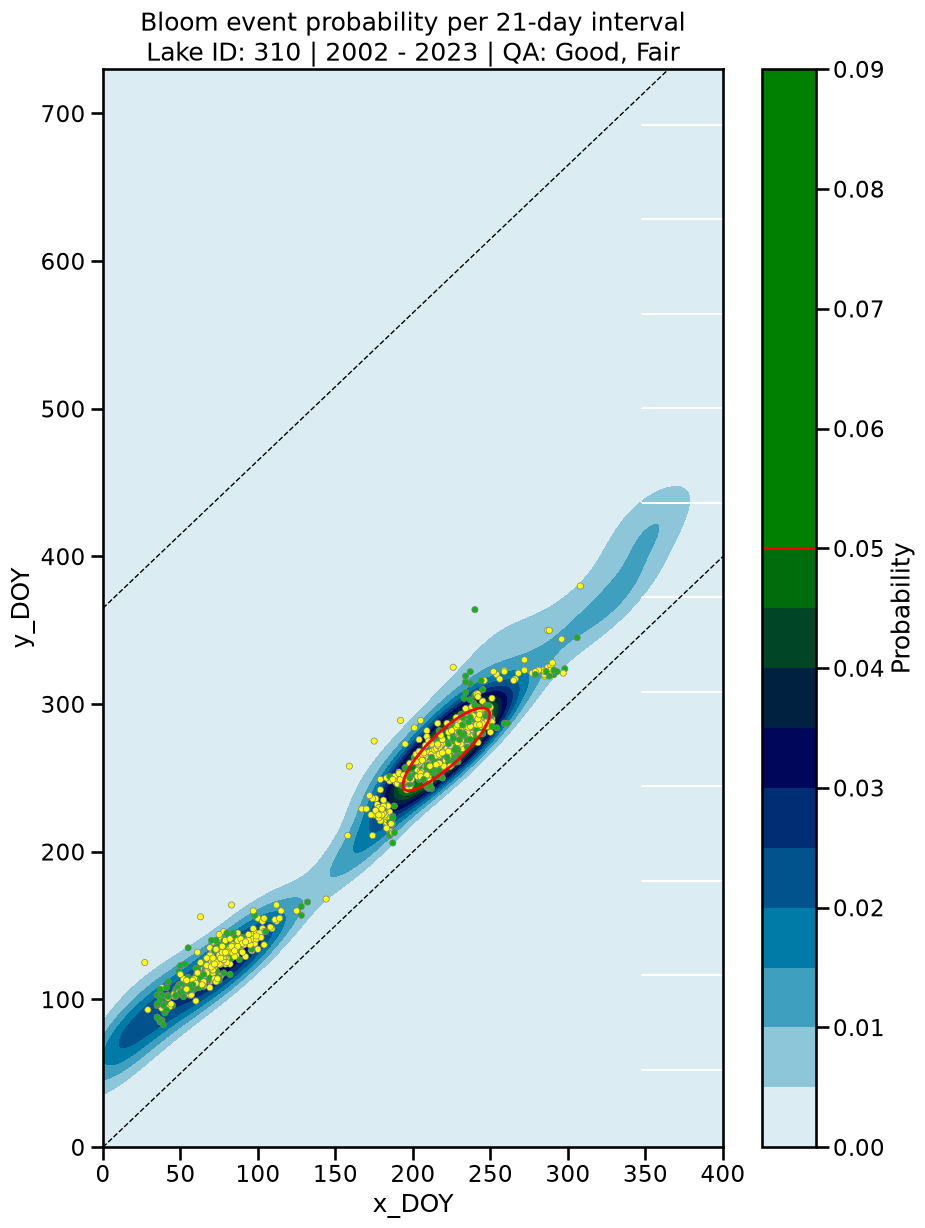

2007


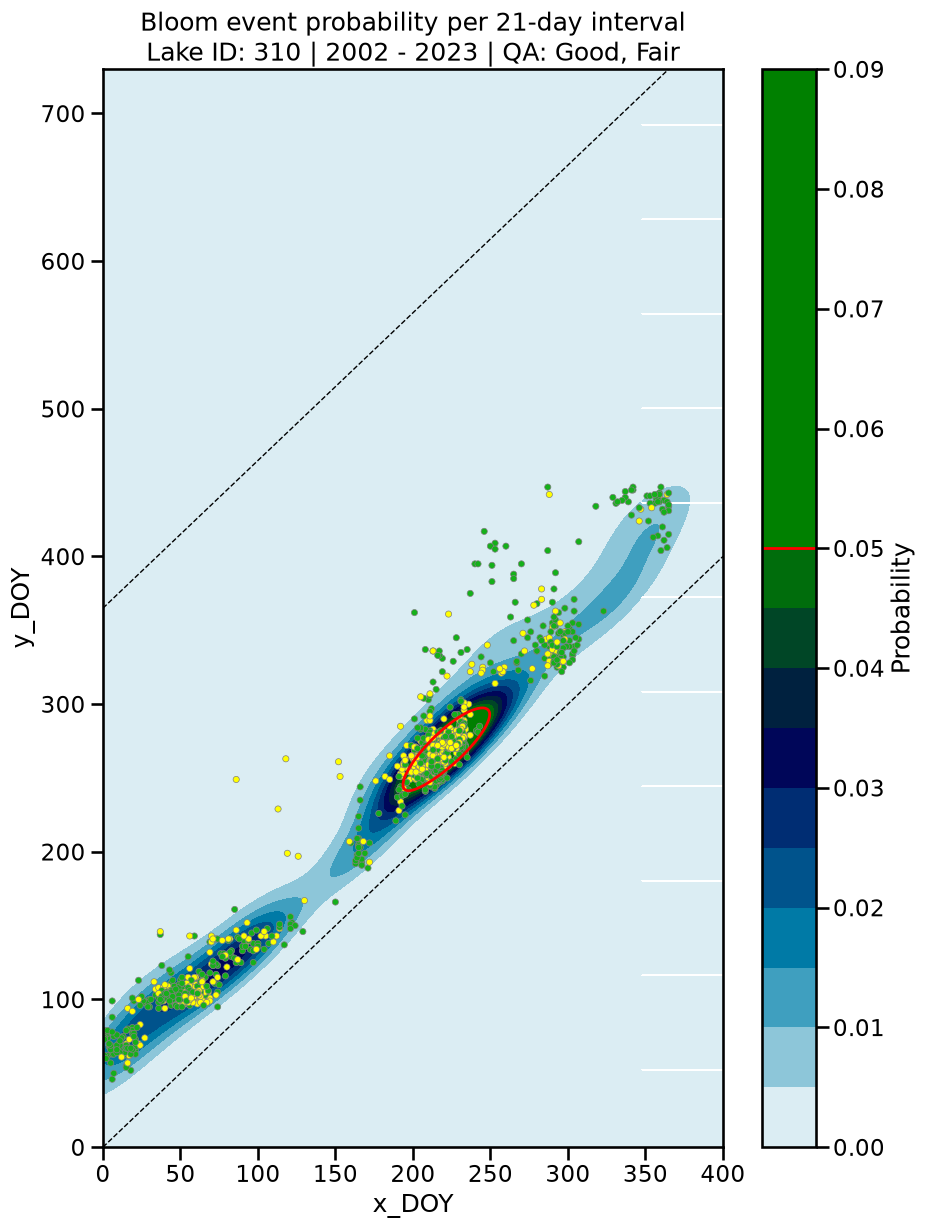

In [18]:
qa_str = f.qa_set_to_str(qa_set)
for yr in np.arange(2005, 2008):
    filtered = filter_pairs_qa_year(paired_df, [yr],qa_set)
    if len(filtered) < 1:
        continue
    filter_doys = prep_df_for_plotting(filtered)

    print(yr)
    fig, ax = plt.subplots(1, 1, figsize=(10, 14))
    eda_instance.lake_bloom_kde_from_fp(ax, bloom_prob_dir/bloom_prob_fp, plt_kwargs=None)
    filter_doys.plot.scatter(ax=ax, x = 'x_DOY', y = 'y_DOY',c='qa_column',edgecolor='grey',linewidths=0.5,cmap= qa_cmap,colorbar=False)
    plt.savefig(f"{lakeID}_{var}{yr}_{qa_str}_bloom_prob.png")
    plt.show()

In [39]:
len(filtered)

0

In [15]:
# Manual QA label creation

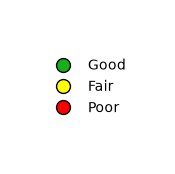

In [19]:
labels = ["Good", "Fair", "Poor"]

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markersize=10,
        markerfacecolor=qa_colors[i],
        markeredgecolor="black",
        label=label,
    )
    for i, label in enumerate(labels)
]

fig, ax = plt.subplots(figsize=(2, 2))
ax.legend(handles=legend_handles, loc="center", frameon=False)
ax.axis("off")

plt.show()